# 02 · Linear Regression (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` (លេខបន្ត → **regression**, ឯកតា $100,000)

## 1. Goal
ទាយ **តម្លៃផ្ទះមេដ្យាន** របស់សង្កាត់មួយ (`MedHouseVal`) ពីចំណូល អាយុផ្ទះ ចំនួនបន្ទប់ និងទីតាំងរបស់វា។ Linear Regression ជា model មូលដ្ឋានសម្រាប់ទាយ **លេខ**
(ឧ. តម្លៃផ្ទះ, ការលក់ខែក្រោយ, ប្រាក់ខែ) ហើយជាគ្រឹះនៃ models ជាច្រើនទៀត។ យើងក៏ប្រៀបធៀប Ridge និង Lasso ផងដែរ។

## Concept
- Model គូស **បន្ទាត់ត្រង់ដែលល្អបំផុត**: `y = w·x + b`
  - `w` (slope / coefficient): ពេល x កើន 1 ឯកតា y ប្រែប្រួលប៉ុន្មាន
  - `b` (intercept): តម្លៃ y ពេល x = 0
- "ល្អបំផុត" មានន័យថា **ផលបូកនៃ error ការេ** (squared errors) រវាងចំណុចពិត និងបន្ទាត់ តូចបំផុត។ ហៅថា **Least Squares**។
- មាន features ច្រើន: `y = w1·x1 + w2·x2 + ... + b` (**Multiple Linear Regression**)។

**ឧបមា "ថ្លៃតាក់ស៊ី":** ថ្លៃជិះ = ថ្លៃចាប់ផ្តើម + (តម្លៃក្នុងមួយ km × ចំនួន km) + (តម្លៃក្នុងមួយនាទី × ចំនួននាទី)។
Linear Regression សន្មតថាតម្លៃផ្ទះដំណើរការបែបដូចគ្នា: feature នីមួយៗមាន "តម្លៃក្នុងមួយឯកតា" ថេរ (coefficient) ហើយ model គ្រាន់តែបូកវា។
ការ train គឺរកតម្លៃទាំងនោះដែលធ្វើឲ្យការទាយនៅជិតតម្លៃពិតបំផុត។

Import libraries។

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

Load clean data។ Columns ទាំងអស់ជា `float64` ដូច្នេះមិនត្រូវការ `dtype=` ទេ។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Train/Test Split
`test_size=0.2`, `random_state=42`។ សម្រាប់ regression គ្មាន `stratify` ទេ ព្រោះ target ជាលេខបន្ត មិនមែន classes។
Split នេះនឹងត្រូវប្រើដដែលក្នុង notebooks 03–09 ដើម្បីឲ្យការប្រៀបធៀបយុត្តិធម៌។

In [3]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 3. Simple Linear Regression: MedHouseVal ~ MedInc (train only)
ចាប់ផ្តើមជាមួយ feature តែមួយ ដើម្បីមើលបន្ទាត់ដោយភ្នែក។ យើង fit លើ **training set តែប៉ុណ្ណោះ** ព្រោះ test set ត្រូវទុកជា data ដែល model មិនដែលឃើញ
សូម្បីតែសម្រាប់ model សាកល្បងក៏ដោយ។ បើ fit លើ data ទាំងអស់ នោះយើងបានមើល test data មុនពេលវាយតម្លៃ។

In [4]:
simple = LinearRegression().fit(X_train[["MedInc"]], y_train)
slope, intercept = simple.coef_[0], simple.intercept_
{"slope ($100k per +1 MedInc)": round(float(slope), 4), "slope in dollars per +$10,000 income": round(float(slope) * 100_000),
 "intercept ($100k)": round(float(intercept), 4)}

{'slope ($100k per +1 MedInc)': 0.4024,
 'slope in dollars per +$10,000 income': 40239,
 'intercept ($100k)': 0.4424}

Scatter plot ជាមួយបន្ទាត់ដែល model រកឃើញ។

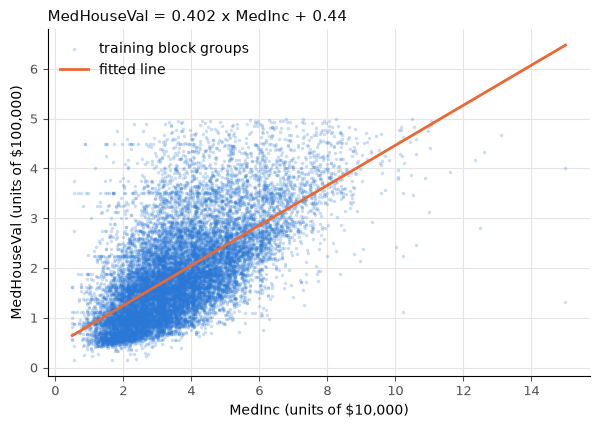

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X_train["MedInc"], y_train, s=6, color=BLUE, alpha=0.25, linewidth=0, label="training block groups")
xs = pd.DataFrame({"MedInc": [X_train["MedInc"].min(), X_train["MedInc"].max()]})
ax.plot(xs["MedInc"], simple.predict(xs), color=ORANGE, linewidth=2, label="fitted line")
ax.set_xlabel("MedInc (units of $10,000)"); ax.set_ylabel("MedHouseVal (units of $100,000)")
ax.set_title(f"MedHouseVal = {slope:.3f} x MedInc + {intercept:.2f}", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False); style(ax)
plt.show()

**អានលទ្ធផល (ជាឯកតាពិត):**
- **Slope:** ចំណូលមេដ្យានកើនឡើង $10,000 → តម្លៃផ្ទះមេដ្យានកើនឡើងប្រហែល **$40,239**។
- **Intercept:** តម្លៃដែល model ទាយសម្រាប់សង្កាត់ដែល `MedInc = 0` (≈ 0.44 = $44,240)។ វាគ្មានន័យក្នុងជីវិតពិតទេ (`MedInc` តូចបំផុតគឺ 0.5) គ្រាន់តែជាចំណុចដែលបន្ទាត់កាត់អ័ក្ស y។
- ពពកចំណុចធំទូលាយជុំវិញបន្ទាត់: ចំណូលតែមួយមិនគ្រប់គ្រាន់ដើម្បីទាយតម្លៃទេ។ សង្កាត់ដែលមានចំណូលដូចគ្នា អាចមានតម្លៃខុសគ្នាពី $100,000 ដល់ $500,000។
  យើងត្រូវការ features ផ្សេងទៀត (ជាពិសេសទីតាំង)។

## 4. Preprocessing (fit on TRAIN only)
- **numeric (ទាំង 8 features):** `StandardScaler` (mean 0, std 1)
- មិនមាន missing values ឬ categorical columns ទេ ដូច្នេះមិនត្រូវការ `SimpleImputer`/`OneHotEncoder` (មើល notebook 01)។

`fit_transform` លើ train, តែ `transform` លើ test → គ្មាន data leakage។
**ហេតុអ្វីត្រូវ scale?** `Population` មានតម្លៃរាប់ពាន់ ចំណែក `AveBedrms` ប្រហែល 1។ សម្រាប់ Linear Regression ធម្មតា scaling មិនផ្លាស់ប្តូរការទាយទេ
ប៉ុន្តែវាធ្វើឲ្យ coefficients **អាចប្រៀបធៀបគ្នាបាន** ហើយវាចាំបាច់សម្រាប់ Ridge/Lasso។

In [6]:
feature_names = X.columns.tolist()
scaler = StandardScaler()
X_train_prep = scaler.fit_transform(X_train)   # fit + transform on train
X_test_prep = scaler.transform(X_test)         # transform ONLY on test
X_train_prep.shape, X_test_prep.shape

((15546, 8), (3887, 8))

Mean ដែលរៀនពី **train តែប៉ុណ្ណោះ** (នឹងត្រូវប្រើលើ test ផងដែរ)។

In [7]:
pd.Series(scaler.mean_, index=feature_names, name="mean (train)").round(3)

MedInc           3.681
HouseAge        28.414
AveRooms         5.253
AveBedrms        1.072
Population    1439.917
AveOccup         2.931
Latitude        35.659
Longitude     -119.583
Name: mean (train), dtype: float64

## 5–7. Baseline, Multiple Linear Regression and metrics
**Metrics (ឯកតាជា $100,000 ដូច target):**
- **MAE** (Mean Absolute Error): ជាមធ្យម model ទាយខុសប៉ុន្មាន។ ងាយយល់បំផុត (`0.43` = $43,000)។
- **MSE** (Mean Squared Error): មធ្យមនៃ error ការេ។ ដាក់ទោស error ធំខ្លាំង។
- **RMSE**: √MSE ត្រលប់មកឯកតាដើមវិញ។ ធំជាង MAE បើមាន error ធំៗ។
- **R²**: ភាគរយនៃបម្រែបម្រួលតម្លៃផ្ទះដែល model ពន្យល់បាន។ 1.0 = ល្អឥតខ្ចោះ, 0 = ដូច baseline។

Function ជំនួយសម្រាប់គណនា metrics ទាំង 4។

In [8]:
def metrics(model, X, y):
    pred = model.predict(X)
    mse = mean_squared_error(y, pred)
    return {"MAE": mean_absolute_error(y, pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y, pred)}

def train_test_table(models):
    rows = {(name, split): metrics(m, Xs, ys)
            for name, m in models.items()
            for split, Xs, ys in [("train", X_train_prep, y_train), ("test", X_test_prep, y_test)]}
    return pd.DataFrame(rows).T.round(3)

**Baseline:** `DummyRegressor(mean)` តែងតែទាយ mean របស់ train។ **Model:** `LinearRegression` ជាមួយ features ទាំងអស់។
ប្រៀបធៀប train និង test: បើ train ល្អជាង test ខ្លាំង → Overfitting។

In [9]:
dummy = DummyRegressor(strategy="mean").fit(X_train_prep, y_train)
lr = LinearRegression().fit(X_train_prep, y_train)
train_test_table({"baseline (mean)": dummy, "LinearRegression": lr})

MAE    MSE   RMSE     R2
baseline (mean)  train  0.779  0.943  0.971  0.000
                 test   0.790  0.958  0.979 -0.000
LinearRegression train  0.438  0.345  0.587  0.634
                 test   0.439  0.349  0.590  0.636

**អានលទ្ធផល:**
- **Baseline** (ទាយ mean ជានិច្ច): MAE 0.790, R² ≈ 0។ នេះជា "គ្មានជំនាញ"។ Model ពិតត្រូវតែឈ្នះលេខនេះ។
- **LinearRegression** (test): **MAE 0.439** (ទាយខុសជាមធ្យមប្រហែល **$43,900**), RMSE 0.590, **R² 0.636** (ពន្យល់បាន ~64% នៃបម្រែបម្រួលតម្លៃ)។
- RMSE (0.590) ធំជាង MAE (0.439): មានកំហុសមួយចំនួនធំជាងមធ្យមច្រើន។
- **Train និង test ស្ទើរតែដូចគ្នា** (R² 0.634 ទល់ 0.636)។ Model **មិន Overfitting** ទេ។ ផ្ទុយទៅវិញ វាអាច **Underfitting**: សាមញ្ញពេក មិនអាចទទួលបានពិន្ទុខ្ពស់ សូម្បីលើ data ដែលវាបានឃើញ។
  ការដែល test ល្អជាង train បន្តិចគឺដោយសារ split ចៃដន្យ (នៅក្នុងកម្រិត noise)។

## 8. Residual plot and predicted vs actual
**Residual = actual − predicted។** Residual plot ល្អមើលទៅដូច "ពពកចៃដន្យ" ជុំវិញបន្ទាត់ 0: គ្មានរាងកោង, គ្មានរាងចីវលោ (funnel)។
បើឃើញរាងកោង (U-shape) → ទំនាក់ទំនងមិនត្រង់ ដែលបន្ទាត់ត្រង់ចាប់មិនបាន។

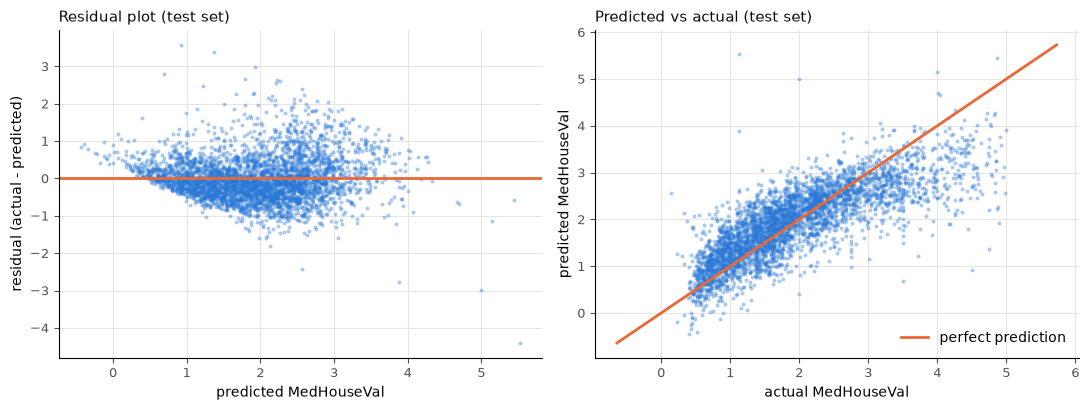

In [10]:
pred_test = lr.predict(X_test_prep)
resid = y_test - pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(pred_test, resid, s=8, color=BLUE, alpha=0.4, linewidth=0)
ax1.axhline(0, color=ORANGE, linewidth=2)
ax1.set_xlabel("predicted MedHouseVal"); ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title("Residual plot (test set)", loc="left", fontsize=11, color=INK); style(ax1)

ax2.scatter(y_test, pred_test, s=8, color=BLUE, alpha=0.4, linewidth=0)
lims = [min(y_test.min(), pred_test.min()) - 0.2, max(y_test.max(), pred_test.max()) + 0.2]
ax2.plot(lims, lims, color=ORANGE, linewidth=2, label="perfect prediction")
ax2.set_xlabel("actual MedHouseVal"); ax2.set_ylabel("predicted MedHouseVal")
ax2.set_title("Predicted vs actual (test set)", loc="left", fontsize=11, color=INK)
ax2.legend(frameon=False); style(ax2)
fig.tight_layout()
plt.show()

រាប់ predictions ដែលអវិជ្ជមាន (តម្លៃផ្ទះមិនអាចអវិជ្ជមាន) និង predictions ដែលលើសពី cap 5.0 ដែលយើងបានដក។

In [11]:
{"negative predictions": int((pred_test < 0).sum()), "predictions above 5.0": int((pred_test > 5.0).sum()),
 "worst under-prediction (actual - predicted)": round(float(resid.max()), 2),
 "worst over-prediction": round(float(resid.min()), 2)}

{'negative predictions': 12,
 'predictions above 5.0': 3,
 'worst under-prediction (actual - predicted)': 3.57,
 'worst over-prediction': -4.4}

**អានលទ្ធផល:**
- **Predicted vs actual (ស្តាំ):** ចំណុចតាមបន្ទាត់ ប៉ុន្តែរាយប៉ាយធំ។ សម្រាប់សង្កាត់ថ្លៃ (actual > 3) ចំណុចភាគច្រើននៅ **ក្រោម** បន្ទាត់: model ទាយ **ទាបពេក**។ សម្រាប់សង្កាត់ថោក model ទាយខ្ពស់បន្តិច។
  Model ទាយ "ទៅរកមធ្យម" ព្រោះវាមិនអាចចាប់យកទំនាក់ទំនងស្មុគស្មាញបាន។
- **Residual plot (ឆ្វេង):** មិនមែនជាពពកគ្មានរាងទេ។ វាមានរាង **ចីវលោ (funnel)**: កាន់តែទាយថ្លៃ កាន់តែមានកំហុសធំ (variance មិនថេរ) ហើយមាន **គែមទ្រេត** នៅពីរចុង។
  គែមទាំងនោះកើតមកពីទិន្នន័យត្រូវបានកាត់ត្រឹម [0.15, 5.0] (យើងបានដក rows ជាប់ cap): `actual − predicted` មិនអាចលើស `5 − predicted` ហើយមិនអាចតិចជាង `0.15 − predicted`។
- មាន predictions អវិជ្ជមាន 12 (តម្លៃផ្ទះមិនអាចអវិជ្ជមានបាន) និង 3 ដែលលើស 5.0។ បន្ទាត់ត្រង់មិនដឹងពីដែនកំណត់ទាំងនេះទេ។
- កំហុសអាក្រក់បំផុត: ទាយទាបជាងតម្លៃពិត 3.57 ($357,000) និងទាយខ្ពស់ជាង 4.40 ($440,000)។

នេះបង្ហាញថាទំនាក់ទំនងពិត **មិនមែនជាបន្ទាត់ត្រង់ទេ** ដូច្នេះ Linear Regression នៅមានអ្វីដែលវាចាប់យកមិនបាន។

## 9. Multicollinearity
**Multicollinearity** = features ដែលទាក់ទងគ្នាខ្លាំង (ឧ. `Latitude` និង `Longitude` ព្រោះរដ្ឋ California លាតសន្ធឹងជាអង្កត់ទ្រូង)។
Model ពិបាកបំបែកថា feature ណាពិតជាបង្កផល ដូច្នេះ coefficients អាចមិនស្ថិតស្ថេរ ឬមានសញ្ញាចម្លែក ទោះបី predictions នៅតែល្អក៏ដោយ។

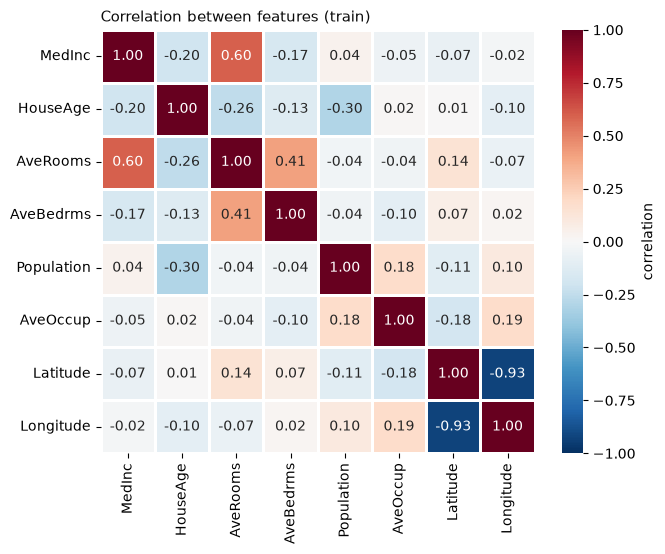

In [12]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", cbar_kws={"label": "correlation"}, ax=ax)
ax.set_title("Correlation between features (train)", loc="left", fontsize=11, color=INK)
plt.show()

Coefficients របស់ LinearRegression (features ត្រូវបាន scale ដូច្នេះ: តម្លៃផ្ទះប្រែប្រួលប៉ុន្មាន $100,000 ពេល feature កើន 1 standard deviation ហើយអ្វីផ្សេងទៀតនៅថេរ)។

In [13]:
coef_lr = pd.Series(lr.coef_, index=feature_names, name="LinearRegression")
pd.concat([coef_lr, pd.Series(lr.intercept_, index=["intercept"], name="LinearRegression")]).round(3).to_frame()

,LinearRegression
MedInc,0.681
HouseAge,0.124
AveRooms,-0.148
AveBedrms,0.127
Population,0.046
AveOccup,-0.222
Latitude,-0.825
Longitude,-0.765
intercept,1.923


**អានលទ្ធផល:**
- **`MedInc` (+0.68)** ជាកត្តាវិជ្ជមានខ្លាំងបំផុត: ចំណូលកើន 1 standard deviation (≈ $15,700) បន្ថែមប្រហែល **$68,000** ទៅតម្លៃទាយ។
- **`Latitude` (−0.83) និង `Longitude` (−0.77)** ធំ និងអវិជ្ជមាន។ ត្រូវអានវាជាគូ: ទៅទិសជើង ឬទិសកើត (ចូលដីគោក ឆ្ងាយពីមាត់សមុទ្រ) → តម្លៃធ្លាក់ចុះ។
  ពួកវាទាក់ទងគ្នាខ្លាំង (heatmap បង្ហាញ ≈ −0.93) ដូច្នេះកុំបកស្រាយមួយៗដាច់ដោយឡែក។
- **`AveOccup` (−0.22):** គ្រួសារមានមនុស្សច្រើនស្ថិតក្នុងតំបន់ថោកជាង។
- **`AveRooms` (−0.15)** ជា **សញ្ញាចម្លែក**: នៅក្នុង notebook 01 correlation របស់វាជាមួយតម្លៃគឺ **វិជ្ជមាន** (+0.15) ប៉ុន្តែ coefficient អវិជ្ជមាន។
  Coefficient គឺជាឥទ្ធិពល **នៅពេលដែល features ផ្សេងទៀតទាំងអស់នៅថេរ**។ ពេលគិតចំណូលនិង `AveBedrms` រួច សញ្ញាប្រែត្រឡប់។ `AveRooms` និង `AveBedrms` ទាក់ទងគ្នា ដូច្នេះ model ផ្ទេរទម្ងន់រវាងពួកវា។
- **Intercept (1.92):** សង្កាត់មធ្យមត្រូវបានទាយថាមានតម្លៃ ≈ $192,000 ដែលជា mean នៃ target ក្នុង training set (ពេល features ទាំងអស់ស្មើ mean)។

**មេរៀន:** កុំអាន coefficient នីមួយៗដាច់ដោយឡែកពេល features ទាក់ទងគ្នាខ្លាំង។ Coefficient មិនដូច correlation ទេ។

## 10. Ridge and Lasso
**Regularization** បន្ថែម "ការពិន័យ" លើ coefficients ធំៗ ដើម្បីឲ្យ model សាមញ្ញ និងស្ថិតស្ថេរជាង។
- **Ridge (L2):** បង្រួម coefficients ទាំងអស់ឲ្យតូច ប៉ុន្តែមិនដល់សូន្យ។ ល្អសម្រាប់ multicollinearity។
- **Lasso (L1):** អាចរុញ coefficients ខ្លះឲ្យ **ស្មើសូន្យ** → ជ្រើស features ដោយស្វ័យប្រវត្តិ (feature selection)។
- `alpha` កាន់តែធំ ការពិន័យកាន់តែខ្លាំង។ (Scaling សំខាន់ណាស់នៅទីនេះ ព្រោះការពិន័យអាស្រ័យលើទំហំ coefficients។)

សាកល្បង `alpha=1.0` សម្រាប់ទាំងពីរ ហើយបន្ថែម Lasso `alpha=0.01`។

In [14]:
ridge = Ridge(alpha=1.0).fit(X_train_prep, y_train)
lasso_1 = Lasso(alpha=1.0).fit(X_train_prep, y_train)
lasso_001 = Lasso(alpha=0.01).fit(X_train_prep, y_train)
models = {"LinearRegression": lr, "Ridge (alpha=1)": ridge, "Lasso (alpha=1)": lasso_1, "Lasso (alpha=0.01)": lasso_001}
train_test_table(models)

MAE    MSE   RMSE     R2
LinearRegression   train  0.438  0.345  0.587  0.634
                   test   0.439  0.349  0.590  0.636
Ridge (alpha=1)    train  0.438  0.345  0.587  0.634
                   test   0.439  0.349  0.590  0.636
Lasso (alpha=1)    train  0.779  0.943  0.971  0.000
                   test   0.790  0.958  0.979 -0.000
Lasso (alpha=0.01) train  0.440  0.348  0.590  0.631
                   test   0.442  0.353  0.594  0.632

ប្រៀបធៀប coefficients របស់ models ទាំងអស់ក្នុងតារាងតែមួយ។

In [15]:
coef_table = pd.DataFrame({name: m.coef_ for name, m in models.items()}, index=feature_names).round(3)
coef_table

,LinearRegression,Ridge (alpha=1),Lasso (alpha=1),Lasso (alpha=0.01)
MedInc,0.681,0.681,0.0,0.660
HouseAge,0.124,0.124,0.0,0.121
AveRooms,-0.148,-0.148,0.0,-0.121
AveBedrms,0.127,0.127,0.0,0.091
Population,0.046,0.046,0.0,0.035
AveOccup,-0.222,-0.222,0.0,-0.215
Latitude,-0.825,-0.824,0.0,-0.697
Longitude,-0.765,-0.765,0.0,-0.635


Features ដែល Lasso កំណត់ coefficient ស្មើសូន្យ (បោះចោល) សម្រាប់ alpha នីមួយៗ។

In [16]:
{name: coef_table.index[coef_table[name] == 0].tolist() for name in ["Lasso (alpha=1)", "Lasso (alpha=0.01)"]}

{'Lasso (alpha=1)': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'Lasso (alpha=0.01)': []}

`alpha` ជា **hyperparameter**។ ព្យាយាមច្រើនតម្លៃ ហើយមើលចំនួន features ដែលនៅសល់ និង test R²។
(នេះគ្រាន់តែជាការបង្ហាញ: ការជ្រើស alpha ដោយ test R² គឺជា leakage ស្រាល → ត្រូវប្រើ Cross-Validation ក្នុង notebook 08។)

In [17]:
rows = []
for alpha in [0.001, 0.01, 0.03, 0.1, 0.3, 1.0]:
    m = Lasso(alpha=alpha).fit(X_train_prep, y_train)
    rows.append({"alpha": alpha, "features kept": int((m.coef_ != 0).sum()), "train R2": m.score(X_train_prep, y_train),
                 "test R2": m.score(X_test_prep, y_test)})
pd.DataFrame(rows).set_index("alpha").round(3)

,features kept,train R2,test R2
alpha,,,
0.001,8,0.634,0.636
0.010,8,0.631,0.632
0.030,8,0.599,0.600
0.100,4,0.481,0.478
0.300,1,0.328,0.323
1.000,0,0.000,-0.000


**អានលទ្ធផល:**
- **Ridge (alpha=1)** ដូច LinearRegression ស្ទើរតែទាំងស្រុង (test R² 0.636 ដូចគ្នា) ហើយ coefficients ស្ទើរតែដូចគ្នា។ ដោយមាន training rows 15,546 និង features តែ 8 នោះ model មិន overfit ទេ
  ដូច្នេះគ្មាន variance ឲ្យ Ridge បន្ថយ។
- **Lasso (alpha=1) ខ្លាំងពេក:** វាកំណត់ **coefficients ទាំង 8 ឲ្យស្មើសូន្យ** ហើយ model ទាយ mean (1.92) សម្រាប់គ្រប់គ្នា។ R² = 0 ដូច baseline ។ ក្នុង scale នេះ alpha=1 ធំជាង signal ណាមួយ។
- **Lasso (alpha=0.01)** រក្សាគ្រប់ features ហើយ R² ធ្លាក់បន្តិច (0.632)។ តារាង alpha បង្ហាញលំនាំ: alpha កាន់តែធំ features កាន់តែតិច (alpha 0.1 → 4 features, 0.3 → ត្រឹម 1) ហើយ R² ធ្លាក់ចុះជានិច្ច។
- **គ្មាន "alpha ល្អបំផុត" ពីលើ 0** ទេ: regularization មិនបង្កើនពិន្ទុនៅទីនេះទេ។ បញ្ហារបស់ Linear model គឺ **bias** (សាមញ្ញពេក) មិនមែន variance ទេ ហើយ regularization ព្យាបាលតែ variance។
- `alpha` ជា **hyperparameter** ដែលត្រូវ tune ដោយ Cross-Validation (notebook 08)។

## 11. Predict for two made-up neighbourhoods
ប្រើ `scaler.transform` (មិនមែន fit) សម្រាប់ data ថ្មី។ សង្កាត់ទាំងពីរនេះនឹងត្រូវប្រើម្តងទៀតក្នុង notebooks ជាបន្តបន្ទាប់។

In [18]:
new_neighbourhoods = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500,
     "AveOccup": 2.8, "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800,
     "AveOccup": 3.4, "Latitude": 36.75, "Longitude": -119.80},
], index=["high income, Los Angeles coast", "low income, inland Central Valley"])
new_prep = scaler.transform(new_neighbourhoods)
new_neighbourhoods.assign(**{f"price_{name}": m.predict(new_prep).round(2) for name, m in models.items()})

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price_LinearRegression,price_Ridge (alpha=1),price_Lasso (alpha=1),price_Lasso (alpha=0.01)
"high income, Los Angeles coast",8.0,25,6.5,1.0,1500,2.8,34.05,-118.4,3.77,3.77,1.92,3.74
"low income, inland Central Valley",2.2,35,4.8,1.1,1800,3.4,36.75,-119.8,0.96,0.96,1.92,1.01


**អានលទ្ធផល:** Linear/Ridge ទាយសង្កាត់ចំណូលខ្ពស់មាត់សមុទ្រ Los Angeles ≈ **3.77** ($377,000) និងសង្កាត់ចំណូលទាបនៅ Central Valley ≈ **0.96** ($96,000)។ ដូចដែលរំពឹង។
Lasso (alpha=1) ទាយ 1.92 សម្រាប់ទាំងពីរ (ព្រោះ coefficients ទាំងអស់សូន្យ)។ Lasso (alpha=0.01) ស្ទើរតែដូច Linear។

## Lesson summary
- **Linear Regression** រកបន្ទាត់ `y = w·x + b` ដែលធ្វើឲ្យ squared errors តូចបំផុត។
- **Slope** ប្រាប់ថា y ប្រែប្រួលប៉ុន្មានពេល x កើន 1 ឯកតា; **intercept** ជា y ពេល x = 0 (មិនតែងតែមានន័យ)។
- **Metrics:** MAE និង RMSE ជាឯកតា $100,000; R² ជាភាគរយដែល model ពន្យល់បាន។ តែងប្រៀបធៀបជាមួយ **baseline** (`DummyRegressor`)។
- លទ្ធផល: **test MAE 0.439, RMSE 0.590, R² 0.636** (baseline R² ≈ 0)។ Train ≈ test → មិន overfit ប៉ុន្តែ **underfit**។
- **Residual plot** ល្អ = ពពកចៃដន្យជុំវិញ 0។ ត្រង់នេះឃើញរាងចីវលោ និង predictions អវិជ្ជមាន → ទំនាក់ទំនងមិនត្រង់។
- **Multicollinearity** (`Latitude`/`Longitude`, `AveRooms`/`AveBedrms`) ធ្វើឲ្យ coefficients មានសញ្ញាចម្លែក ទោះបី predictions ល្អក៏ដោយ។
- **Ridge** បង្រួម coefficients; **Lasso** អាចកំណត់ខ្លះជាសូន្យ។ លើ data នេះ ទាំងពីរមិនឈ្នះ Linear ធម្មតាទេ ព្រោះបញ្ហាគឺ bias មិនមែន variance។
- Preprocessing (scaling) តែង `fit` លើ train តែប៉ុណ្ណោះ។
- ការបន្ត: Linear model ទទួលបាន R² ≈ 0.64។ Notebooks 03–07 សាកល្បង models ដែលអាចចាប់យកទំនាក់ទំនង **មិនត្រង់** (ទីតាំង × ចំណូល)។